In [13]:
import ee
import geemap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [14]:
#authenticate and initalize ee
ee.Authenticate()
ee.Initialize(project='my-project11-429606')

In [15]:
admin = ee.FeatureCollection(
    "FAO/GAUL/2025/level2"
)

print("Total features:", admin.size().getInfo())
print("First feature:")
print(admin.first().toDictionary().getInfo())


/usr/local/lib/python3.13/dist-packages/ee/data.py:335: UserWarning: Your project has exceeded the compute quota of its noncommercial tier and is currently in restricted mode.
  warnings.warn(


Total features: 43819
First feature:
{'CONTINENT': 'Africa', 'DISP_EN': 'Adrar, Adrar, Algeria', 'FID': 163, 'GAUL0_CODE': 101, 'GAUL0_NAME': 'Algeria', 'GAUL1_CODE': 1001, 'GAUL1_NAME': 'Adrar', 'GAUL2_CODE': 100001, 'GAUL2_NAME': 'Adrar', 'ISO3_CODE': 'DZA', 'MAP_CODE': 'DZA'}


In [16]:
# Load GAUL 2025 Level 2 boundaries
admin = ee.FeatureCollection(
    "FAO/GAUL/2025/level2"
)

# Filter Nigeria
nigeria = admin.filter(
    ee.Filter.eq("GAUL0_NAME", "Nigeria")
)

# Inspect state names
states = nigeria.aggregate_array(
    "GAUL1_NAME"
).distinct().sort()

print("States in the dataset:")
print(states.getInfo())

States in the dataset:
['Abia', 'Adamawa', 'Akwa Lbom', 'Anambra', 'Bauchi', 'Bayelsa', 'Benue', 'Borno', 'Cross River', 'Delta', 'Ebonyi', 'Edo', 'Ekiti', 'Enugu', 'Federal Capital Territory', 'Gombe', 'Imo', 'Jigawa', 'Kaduna', 'Kano', 'Katsina', 'Kebbi', 'Kogi', 'Kwara', 'Lagos', 'Nassarawa', 'Niger', 'Ogun', 'Ondo', 'Osun', 'Oyo', 'Plateau', 'Rivers', 'Sokoto', 'Taraba', 'Yobe', 'Zamfara']


In [17]:
# Extract Lagos State
lagos = nigeria.filter(
    ee.Filter.eq("GAUL1_NAME", "Lagos")
)

# Extract Lagos State geometry
lagos_geometry = lagos.geometry()

# Extract the 20 LGAs
lagos_lgas = lagos

print("Lagos features:", lagos.size().getInfo())
print("Lagos geometry loaded successfully.")
print("LGA names:", lagos.aggregate_array("GAUL2_NAME").getInfo())

Lagos features: 20
Lagos geometry loaded successfully.
LGA names: ['Alimosho', 'Amuwo-Odofin', 'Epe', 'Eti-Osa', 'Ikorodu', 'Kosofe', 'Mushin', 'Ojo', 'Oshodi-Isolo', 'Shomolu', 'Surulere', 'Apapa', 'Ibeju/Lekki', 'Ifako-Ijaye', 'Ikeja', 'Agege', 'Ajeromi-Ifelodun', 'Lagos Island', 'Lagos Mainland', 'Badagry']


In [18]:
def mask_sentinel2(image):
    scl = image.select("SCL")

    clear_mask = (
        scl.neq(1)
        .And(scl.neq(2))
        .And(scl.neq(3))
        .And(scl.neq(7))
        .And(scl.neq(8))
        .And(scl.neq(9))
        .And(scl.neq(10))
        .And(scl.neq(11))
    )

    reflectance = image.select(
        ["B2", "B3", "B4", "B8"]
    ).multiply(0.0001)

    return (
        image.addBands(reflectance, overwrite=True)
        .updateMask(clear_mask)
        .copyProperties(image, ["system:time_start"])
    )

In [19]:
def add_vegetation_indices(image):

    # Calculate NDVI
    ndvi = image.normalizedDifference(
        ["B8", "B4"]
    ).rename("NDVI")

    # Extract reflectance bands
    nir = image.select("B8")
    red = image.select("B4")
    blue = image.select("B2")

    # Calculate EVI denominator
    denominator = (
        nir.add(red.multiply(6))
        .subtract(blue.multiply(7.5))
        .add(1)
    )

    # Calculate EVI
    evi = image.expression(
        "2.5 * ((NIR - RED) / DENOM)",
        {
            "NIR": nir,
            "RED": red,
            "DENOM": denominator
        }
    ).rename("EVI")

    # Remove unstable denominator values and implausible EVI outliers
    valid_evi = (
        denominator.abs().gt(0.1)
        .And(evi.gte(-1))
        .And(evi.lte(1))
    )

    evi = evi.updateMask(valid_evi)

    return image.addBands(
        [ndvi, evi],
        overwrite=True
    )

In [20]:
years = ee.List.sequence(2019, 2025)

def make_annual_composite(year):

    year = ee.Number(year)

    start = ee.Date.fromYMD(year, 5, 1)
    end = ee.Date.fromYMD(year, 11, 1)

    collection = (
        ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
        .filterBounds(lagos_geometry)
        .filterDate(start, end)
        .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 90))
        .map(mask_sentinel2)
        .map(add_vegetation_indices)
    )

    composite = (
        collection
        .select(["NDVI", "EVI"])
        .median()
        .clip(lagos_geometry)
        .set("year", year)
        .set("scene_count", collection.size())
        .set("system:time_start", start.millis())
    )

    return composite


annual_composites = ee.ImageCollection.fromImages(
    years.map(make_annual_composite)
)

print(
    "Annual composites:",
    annual_composites.size().getInfo()
)

Annual composites: 7


In [21]:
# Retrieve annual metadata
composite_years = annual_composites.aggregate_array(
    "year"
).getInfo()

scene_counts = annual_composites.aggregate_array(
    "scene_count"
).getInfo()

# Display results
for year, count in zip(composite_years, scene_counts):
    print(f"{year}: {count} Sentinel-2 scenes")

2019: 42 Sentinel-2 scenes
2020: 59 Sentinel-2 scenes
2021: 67 Sentinel-2 scenes
2022: 41 Sentinel-2 scenes
2023: 52 Sentinel-2 scenes
2024: 58 Sentinel-2 scenes
2025: 77 Sentinel-2 scenes


In [22]:
# Calculate annual mean NDVI and EVI for Lagos State

def calculate_state_statistics(image):

    year = image.get("year")

    stats = image.reduceRegion(
        reducer=ee.Reducer.mean(),
        geometry=lagos_geometry,
        scale=10,
        maxPixels=1e13,
        tileScale=4
    )

    return ee.Feature(None, {
        "year": year,
        "NDVI": stats.get("NDVI"),
        "EVI": stats.get("EVI")
    })


# Generate state-wide annual statistics
state_statistics = ee.FeatureCollection(
    annual_composites.map(calculate_state_statistics)
)

print("Annual records:", state_statistics.size().getInfo())

Annual records: 7


In [23]:
# Function to calculate mean NDVI and EVI for each LGA
def calculate_lga_statistics(image):

    year = image.get("year")

    statistics = image.select(["NDVI", "EVI"]).reduceRegions(
        collection=lagos_lgas,
        reducer=ee.Reducer.mean(),
        scale=10,
        tileScale=4
    )

    # Attach the year to each LGA record
    statistics = statistics.map(
        lambda feature: ee.Feature(feature).set("year", year)
    )

    return statistics


# Calculate statistics across all annual composites
lga_statistics = ee.FeatureCollection(
    annual_composites.map(calculate_lga_statistics)
).flatten()

print("Total LGA records:", lga_statistics.size().getInfo())

Total LGA records: 140


In [24]:
state_results = state_statistics.sort("year").getInfo()

for feature in state_results["features"]:
    properties = feature["properties"]

    print(
        f"Year: {properties['year']} | "
        f"NDVI: {properties['NDVI']:.4f} | "
        f"EVI: {properties['EVI']:.4f}"
    )

Year: 2019 | NDVI: 0.3561 | EVI: 0.2959
Year: 2020 | NDVI: 0.3487 | EVI: 0.2824
Year: 2021 | NDVI: 0.3534 | EVI: 0.2928
Year: 2022 | NDVI: 0.3368 | EVI: 0.2985
Year: 2023 | NDVI: 0.3688 | EVI: 0.3037
Year: 2024 | NDVI: 0.3668 | EVI: 0.2914
Year: 2025 | NDVI: 0.3461 | EVI: 0.2961


In [25]:
# Display the first five records
sample_records = lga_statistics.limit(5).getInfo()

for feature in sample_records["features"]:
    print(feature["properties"])

{'CONTINENT': 'Africa', 'DISP_EN': 'Alimosho, Lagos, Nigeria', 'EVI': 0.23915626382524066, 'FID': 25559, 'GAUL0_CODE': 151, 'GAUL0_NAME': 'Nigeria', 'GAUL1_CODE': 1541, 'GAUL1_NAME': 'Lagos', 'GAUL2_CODE': 105138, 'GAUL2_NAME': 'Alimosho', 'ISO3_CODE': 'NGA', 'MAP_CODE': 'NGA', 'NDVI': 0.2680654553602919, 'year': 2019}
{'CONTINENT': 'Africa', 'DISP_EN': 'Amuwo-Odofin, Lagos, Nigeria', 'EVI': 0.2315386359794784, 'FID': 25560, 'GAUL0_CODE': 151, 'GAUL0_NAME': 'Nigeria', 'GAUL1_CODE': 1541, 'GAUL1_NAME': 'Lagos', 'GAUL2_CODE': 105139, 'GAUL2_NAME': 'Amuwo-Odofin', 'ISO3_CODE': 'NGA', 'MAP_CODE': 'NGA', 'NDVI': 0.2831685798486487, 'year': 2019}
{'CONTINENT': 'Africa', 'DISP_EN': 'Epe, Lagos, Nigeria', 'EVI': 0.3362160891884638, 'FID': 25563, 'GAUL0_CODE': 151, 'GAUL0_NAME': 'Nigeria', 'GAUL1_CODE': 1541, 'GAUL1_NAME': 'Lagos', 'GAUL2_CODE': 105142, 'GAUL2_NAME': 'Epe', 'ISO3_CODE': 'NGA', 'MAP_CODE': 'NGA', 'NDVI': 0.4081263953753467, 'year': 2019}
{'CONTINENT': 'Africa', 'DISP_EN': 'Eti-O

Visualisation

In [27]:
import numpy as np

# Retrieve the corrected LGA statistics
results = lga_statistics.getInfo()

# Convert Earth Engine results into a DataFrame
records = [
    feature["properties"]
    for feature in results["features"]
]

df = pd.DataFrame(records)

# Keep only the required columns
df = df[["GAUL2_NAME", "year", "NDVI", "EVI"]]

# Convert data types
df["year"] = df["year"].astype(int)
df["NDVI"] = pd.to_numeric(df["NDVI"], errors="coerce")
df["EVI"] = pd.to_numeric(df["EVI"], errors="coerce")

print(df.head())
print("\nDataset dimensions:", df.shape)
print("\nMissing values:")
print(df[["NDVI", "EVI"]].isna().sum())

     GAUL2_NAME  year      NDVI       EVI
0      Alimosho  2019  0.268065  0.239156
1  Amuwo-Odofin  2019  0.283169  0.231539
2           Epe  2019  0.408126  0.336216
3       Eti-Osa  2019  0.275091  0.213477
4       Ikorodu  2019  0.210671  0.206875

Dataset dimensions: (140, 4)

Missing values:
NDVI    0
EVI     0
dtype: int64


/usr/local/lib/python3.13/dist-packages/ee/data.py:335: UserWarning: Your project has exceeded the compute quota of its noncommercial tier and is currently in restricted mode.
  warnings.warn(


In [29]:
# Keep the original dataset
df_clean = df.copy()

# Check missing values by year
print("Missing values by year:")

print(
    df_clean.groupby("year")[["NDVI", "EVI"]]
    .apply(lambda x: x.isna().sum())
)

# Confirm dataset dimensions
print("\nDataset dimensions:", df_clean.shape)

# Confirm missing records
print(
    "\nRecords with missing indices:",
    df_clean[df_clean[["NDVI", "EVI"]].isna().any(axis=1)]
    [["GAUL2_NAME", "year", "NDVI", "EVI"]]
)

Missing values by year:
      NDVI  EVI
year           
2019     0    0
2020     0    0
2021     0    0
2022     0    0
2023     0    0
2024     0    0
2025     0    0

Dataset dimensions: (140, 4)

Records with missing indices: Empty DataFrame
Columns: [GAUL2_NAME, year, NDVI, EVI]
Index: []


In [30]:
# Identify LGAs with valid observations in both endpoint years

valid_lgas = (
    df[df["year"].isin([2019, 2025])]
    .groupby("GAUL2_NAME")
    .filter(
        lambda x: (
            len(x) == 2 and
            x[["NDVI", "EVI"]].notna().all().all()
        )
    )["GAUL2_NAME"].unique()
)

comparison_df = df[
    df["GAUL2_NAME"].isin(valid_lgas)
].copy()

print("LGAs available for endpoint comparison:", len(valid_lgas))
print("Comparison dataset:", comparison_df.shape)

LGAs available for endpoint comparison: 20
Comparison dataset: (140, 4)


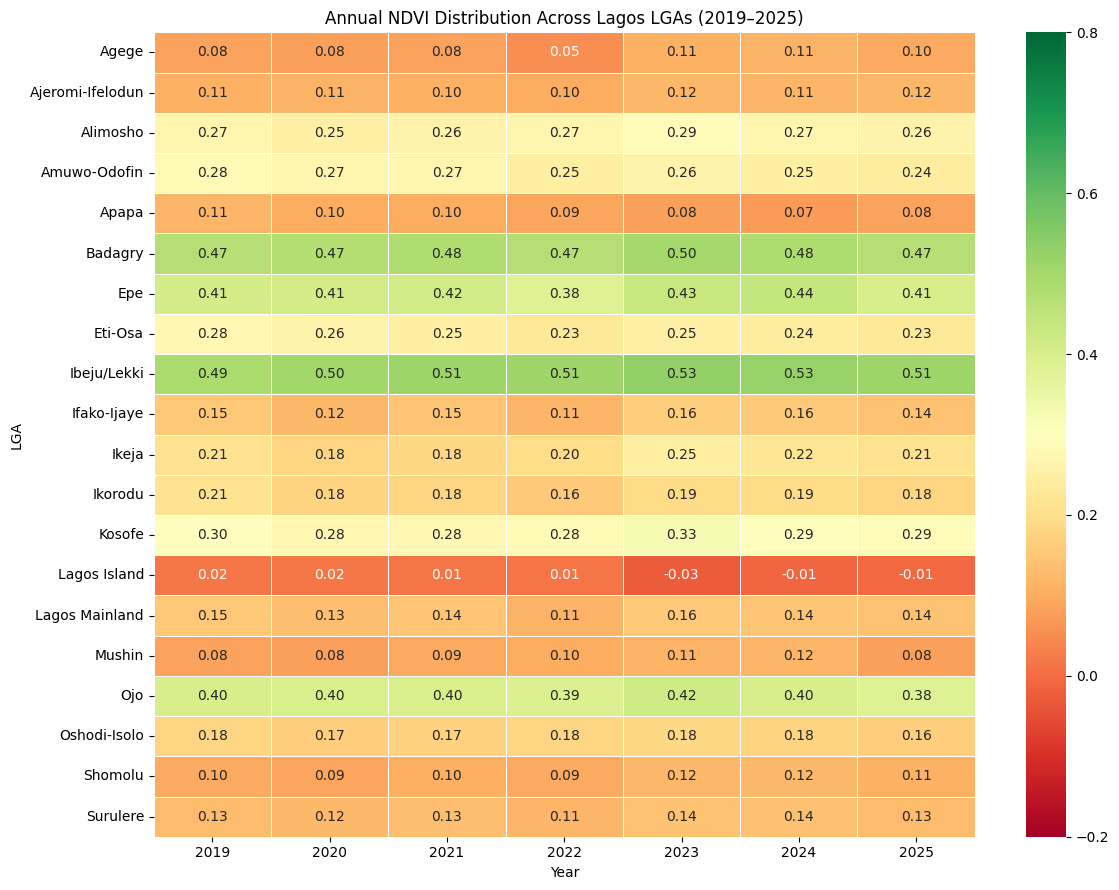

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

ndvi_pivot = comparison_df.pivot(
    index="GAUL2_NAME",
    columns="year",
    values="NDVI"
).sort_index()

plt.figure(figsize=(12, 9))

sns.heatmap(
    ndvi_pivot,
    annot=True,
    fmt=".2f",
    cmap="RdYlGn",
    linewidths=0.5,
    vmin=-0.2,
    vmax=0.8
)

plt.title("Annual NDVI Distribution Across Lagos LGAs (2019–2025)")
plt.xlabel("Year")
plt.ylabel("LGA")
plt.tight_layout()
plt.show()

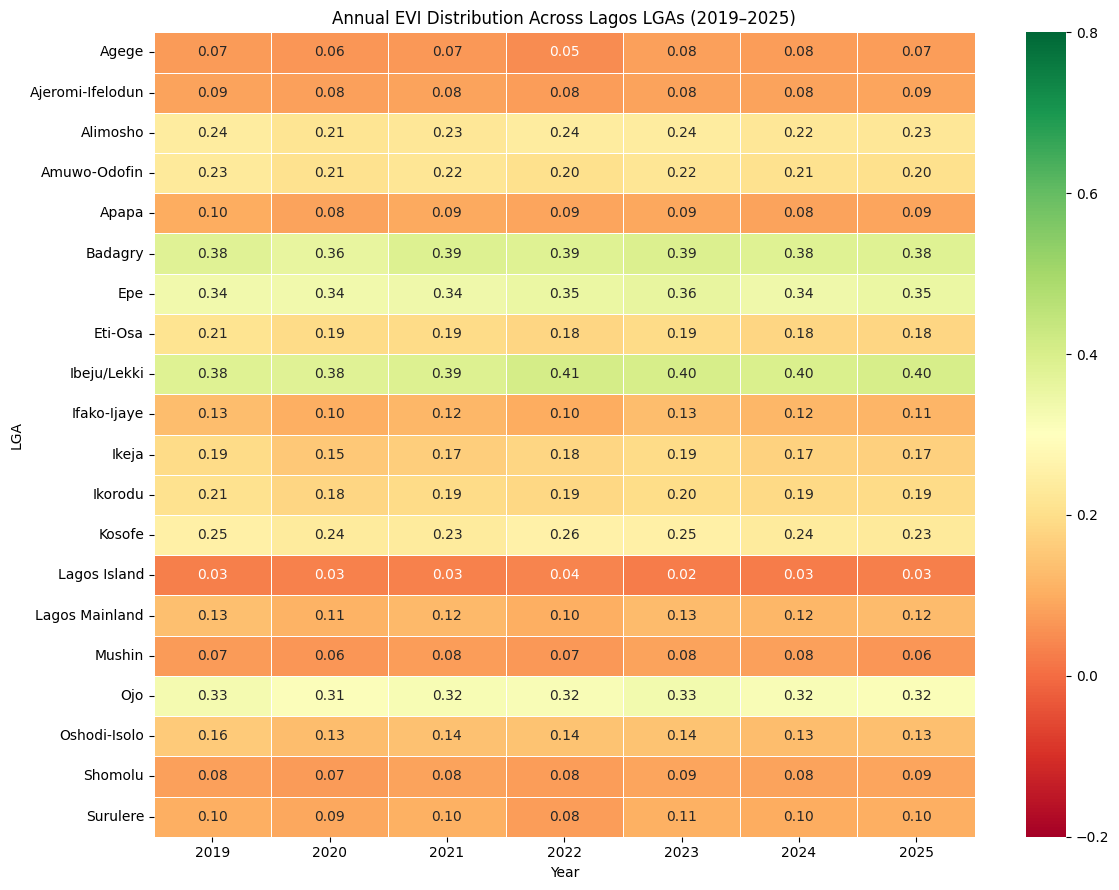

In [32]:
evi_pivot = comparison_df.pivot(
    index="GAUL2_NAME",
    columns="year",
    values="EVI"
).sort_index()

plt.figure(figsize=(12, 9))

sns.heatmap(
    evi_pivot,
    annot=True,
    fmt=".2f",
    cmap="RdYlGn",
    linewidths=0.5,
    vmin=-0.2,
    vmax=0.8
)

plt.title("Annual EVI Distribution Across Lagos LGAs (2019–2025)")
plt.xlabel("Year")
plt.ylabel("LGA")
plt.tight_layout()
plt.show()

In [33]:
ndvi_change = (
    ndvi_pivot[2025] - ndvi_pivot[2019]
).sort_values()

evi_change = (
    evi_pivot[2025] - evi_pivot[2019]
).sort_values()

print("NDVI change (2019–2025):")
print(ndvi_change.round(4))

print("\nEVI change (2019–2025):")
print(evi_change.round(4))

NDVI change (2019–2025):
GAUL2_NAME
Eti-Osa            -0.0493
Amuwo-Odofin       -0.0453
Apapa              -0.0315
Ikorodu            -0.0297
Lagos Island       -0.0235
Ojo                -0.0181
Oshodi-Isolo       -0.0177
Ifako-Ijaye        -0.0117
Lagos Mainland     -0.0114
Kosofe             -0.0088
Alimosho           -0.0045
Mushin             -0.0042
Epe                -0.0027
Ikeja              -0.0017
Surulere           -0.0015
Badagry            -0.0012
Ajeromi-Ifelodun    0.0097
Shomolu             0.0115
Agege               0.0144
Ibeju/Lekki         0.0250
dtype: float64

EVI change (2019–2025):
GAUL2_NAME
Eti-Osa            -0.0335
Amuwo-Odofin       -0.0272
Oshodi-Isolo       -0.0241
Ikeja              -0.0212
Kosofe             -0.0206
Ikorodu            -0.0159
Ifako-Ijaye        -0.0158
Alimosho           -0.0135
Ojo                -0.0133
Apapa              -0.0088
Lagos Mainland     -0.0078
Mushin             -0.0064
Surulere           -0.0028
Lagos Island       -0.

/usr/local/lib/python3.13/dist-packages/ee/data.py:335: UserWarning: Your project has exceeded the compute quota of its noncommercial tier and is currently in restricted mode.
  warnings.warn(


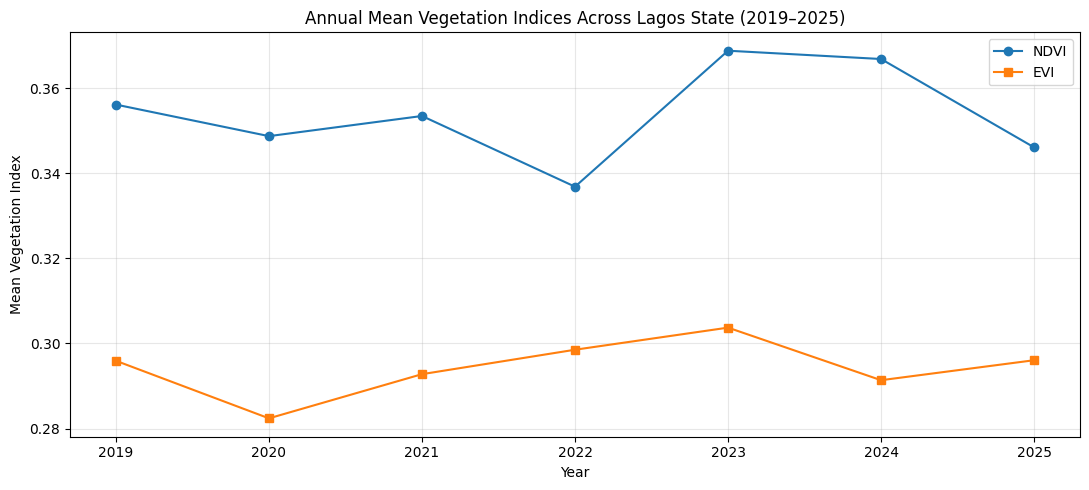

In [34]:
# Prepare state-wide annual statistics
state_df = pd.DataFrame(
    [
        feature["properties"]
        for feature in state_statistics.getInfo()["features"]
    ]
)

state_df["year"] = state_df["year"].astype(int)
state_df = state_df.sort_values("year")

# Plot annual NDVI and EVI trends
fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    state_df["year"],
    state_df["NDVI"],
    marker="o",
    label="NDVI"
)

ax.plot(
    state_df["year"],
    state_df["EVI"],
    marker="s",
    label="EVI"
)

ax.set_title("Annual Mean Vegetation Indices Across Lagos State (2019–2025)")
ax.set_xlabel("Year")
ax.set_ylabel("Mean Vegetation Index")
ax.set_xticks(range(2019, 2026))
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

In [35]:
# Prepare annual NDVI images for animation

ndvi_frames = annual_composites.map(
    lambda image: (
        image.select("NDVI")
        .visualize(
            min=-0.2,
            max=0.8,
            palette=[
                "#a50026",
                "#fdae61",
                "#ffffbf",
                "#a6d96a",
                "#1a9850"
            ]
        )
        .set(
            "system:time_start",
            image.get("system:time_start")
        )
    )
)

ndvi_frames = ndvi_frames.sort("system:time_start")

print("Animation frames:", ndvi_frames.size().getInfo())

Animation frames: 7


/usr/local/lib/python3.13/dist-packages/ee/data.py:335: UserWarning: Your project has exceeded the compute quota of its noncommercial tier and is currently in restricted mode.
  warnings.warn(
